In [1]:
import os
import glob
import json
import random
import time
import torch
import pickle
import numpy as np
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, FuncFormatter, MaxNLocator
from PIL import Image

# ---------------------------------------------------------------- figure style (used by all plots)
# Colorblind-safe categorical hues (blue / orange), a neutral ink for clean accuracy and references,
# and a single-hue blue ramp for the ordered quantity "temperature" (light = low T, dark = high T).
COLORS = {'clean': '#3d3d3a', 'ce': '#2a78d6', 'margin': '#eb6834', 'reference': '#8a8a85'}
TEMPERATURE_CMAP = LinearSegmentedColormap.from_list('temperature', ['#6da7ec', '#0d366b'])

plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans', 'font.size': 10, 'mathtext.fontset': 'dejavusans',
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.8,
    'axes.edgecolor': '#3d3d3a', 'axes.labelcolor': '#1f1f1d', 'xtick.color': '#3d3d3a', 'ytick.color': '#3d3d3a',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'lines.markersize': 6.5,
    'pdf.fonttype': 42, 'ps.fonttype': 42,   # embed TrueType fonts (editable text in the PDF)
})


def legend_above(fig, handles, labels, ncol, title=None):
    """One shared legend centred above all panels (keeps the data area free)."""
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=ncol, title=title,
               handlelength=2.2, columnspacing=1.6)


def save_figure(fig, name):
    """Save a figure as vector PDF (for the report) and 300 dpi PNG into OUTPUT_DIR."""
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(OUTPUT_DIR, f'{name}.{ext}'))



In [2]:
# Prepare environment, dataset and device
# Detect environment and get num_workers
def get_num_workers():
    """ Dynamically determine num_workers based on the environment. """
    if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:  # Running in Kaggle
        print("Running on Kaggle environment")
        return min(8, os.cpu_count())  # Kaggle typically provides more CPU cores
    elif 'COLAB_GPU' in os.environ:  # Running in Colab
        print("Running on Colab environment")
        return min(4, os.cpu_count())  # Colab usually has 2 CPU cores in free tier
    else:
        print("Running on a local or unknown environment")
        # On Windows, DataLoader workers cannot pickle classes defined inside a notebook
        return 0 if os.name == 'nt' else min(2, os.cpu_count())

num_workers = get_num_workers()

class CustomCIFAR10Dataset(Dataset):
    def __init__(self, root, train=True, transform=None):
        self.transform = transform
        self.data = []
        self.targets = []

        if train:
            for i in range(1, 6):
                file_path = os.path.join(root, f"data_batch_{i}")
                with open(file_path, "rb") as f:
                    batch = pickle.load(f, encoding="bytes")
                    self.data.append(batch[b"data"])
                    self.targets.extend(batch[b"labels"])
            self.data = np.vstack(self.data).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        else:
            file_path = os.path.join(root, "test_batch")
            with open(file_path, "rb") as f:
                batch = pickle.load(f, encoding="bytes")
                self.data = batch[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
                self.targets = batch[b"labels"]

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        img, target = self.data[index], self.targets[index]
        img = Image.fromarray(img)  # Convert to PIL image
        if self.transform:
            img = self.transform(img)
        return img, target

# Data preprocessing
# Training uses light, standard CIFAR augmentation (random crop + horizontal flip) only.
# Heavier augmentation (rotation, color jitter) likely contributed to underfitting in an earlier run
# (train loss ~0.9, 75.8% test accuracy after 50 epochs), and
# would add another source of robustness that is hard to separate from the effect of distillation.
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),        # Random crop to 32x32 after 4-pixel padding
    transforms.RandomHorizontalFlip(),           # Random horizontal flip
    transforms.ToTensor(),                       # Convert to tensor
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))  # Normalize
])

transform_test = transforms.Compose([
    transforms.ToTensor(),  # Convert to tensor
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))  # Normalize
])
# Paths depend on the environment.
# OUTPUT_DIR: where new checkpoints / histories are written.
# CHECKPOINT_SEARCH_DIRS: where existing checkpoints are looked up (searched recursively),
# so models saved by an earlier Kaggle run can be attached as an input dataset and reused.
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
if IS_KAGGLE:
    root_path = '/kaggle/input/d/juedu5/deeplearning/cifar-10-batches-py'
    OUTPUT_DIR = '/kaggle/working'
    CHECKPOINT_SEARCH_DIRS = ['/kaggle/working', '/kaggle/input']
else:
    root_path = 'cifar-10-batches-py'
    OUTPUT_DIR = 'checkpoints'
    CHECKPOINT_SEARCH_DIRS = ['checkpoints']
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Hold out a fixed validation set from the 50,000 training images.
# The validation set is used to monitor training and to check convergence;
# the test set is only used for the final evaluation.
VAL_SIZE = 5000
SPLIT_SEED = 0
full_trainset = CustomCIFAR10Dataset(root=root_path, train=True, transform=transform_train)
full_trainset_eval = CustomCIFAR10Dataset(root=root_path, train=True, transform=transform_test)  # same images, no augmentation
split = np.random.RandomState(SPLIT_SEED).permutation(len(full_trainset))
trainset = Subset(full_trainset, split[VAL_SIZE:])
valset = Subset(full_trainset_eval, split[:VAL_SIZE])
testset = CustomCIFAR10Dataset(root=root_path, train=False, transform=transform_test)
print(f"Train: {len(trainset)}, validation: {len(valset)}, test: {len(testset)}")

trainloader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=num_workers)
valloader = DataLoader(valset, batch_size=128, shuffle=False, num_workers=num_workers)
testloader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=num_workers)

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cpu":
    print("Warning: GPU not available. This will be slow for large datasets.")

Running on Kaggle environment
Train: 45000, validation: 5000, test: 10000
Using device: cuda


In [3]:
def initialize_weights(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)

In [4]:
# Define the CIFAR10 model class
class CIFAR10Model(nn.Module):
    def __init__(self):
        super(CIFAR10Model, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Fully connected layers
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),  # Dropout layer with probability 0.5
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10)  # Output layer for 10 classes
        )


    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.fc_layers(x)
        return x
  

In [5]:
# Function to evaluate the model
def evaluate_model(model, testloader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

# Training at temperature T

For every temperature T in `TEMPERATURES`:

1. **Teacher**: trained on hard labels with a softmax at temperature T, i.e. cross-entropy on `softmax(z / T)`.
2. **Student** (same architecture): trained to match the teacher's soft labels `softmax(z_teacher / T)`, also at temperature T. Soft labels are computed on the fly for each (augmented) batch.
3. **Test time**: both models are used at T = 1, i.e. on their raw logits.

`teacher_T1` is the model **without distillation** (ordinary training). `student_T1` is distillation at T = 1 (soft labels, but no temperature).

**Training protocol** (identical for all models): SGD, no loss scaling, no gradient clipping, `EPOCHS` = 50 epochs,
paired seeds (all teachers start from the same initialization, all students from the same initialization).

Temperature slows down learning, differently for teachers and students:

* Teacher: the gradient of `CE(z / T, y)` w.r.t. the logits is `(softmax(z / T) - y) / T`, i.e. it shrinks like 1/T.
* Student: the gradient of the KL loss w.r.t. the student logits is `(p_student - p_teacher) / T`. Depending on the
  scale of the logits relative to T, the probability difference itself can also shrink with T, so the gradient shrinks
  somewhere between 1/T and 1/T^2.

Whether this matters is checked on the validation set after training (see the validation check table below);
the check is a validation-performance check, not a proof of convergence. If a temperature is flagged, inspect its
curves; if it is still improving, add it to `EPOCHS_OVERRIDE` (e.g. `{50: 100}`) and report the epochs used with the results.

**Checkpoints** are named `{role}_T{T}_e{epochs}.pth` (e.g. `teacher_T20_e50.pth`). Next to each checkpoint a
`.meta.json` file stores the full training configuration (data split, augmentation, optimizer, seed, epochs and,
for students, the teacher it was distilled from) together with the training history. An existing checkpoint is only
reused if its stored configuration equals the current one; a checkpoint with the same name but a different
configuration raises an error instead of being loaded silently.

In [6]:
# Experiment configuration
TEMPERATURES = [1, 50]
EPOCHS = 50            # default number of epochs for every teacher and student
EPOCHS_OVERRIDE = {}   # e.g. {50: 100}: train teacher and student of T=50 for 100 epochs
SEED_TEACHER = 0       # paired seeds: the same initialization for every temperature
SEED_STUDENT = 1

# Optimizer schedule (shared by teachers and students).
# Learning rate and momentum are decayed NUM_DECAYS times, evenly spread over training:
# with 50 epochs this is every 10 epochs; with 100 epochs every 20 epochs.
# The paper is inconsistent here: its text says lr x0.95 every 10 epochs, its Table II says x0.5.
INITIAL_LR = 0.01
INITIAL_MOMENTUM = 0.9
LR_DECAY = 0.5         # learning rate multiplied by this factor at every decay step
MOMENTUM_DECAY = 0.5   # momentum multiplied by this factor at every decay step (paper: 0.5)

NUM_DECAYS = 5
MIN_MOMENTUM = 0.1

# Validation check, decided before looking at the results:
MAX_ACC_GAP = 2.0      # final val accuracy at most 2 points below the model without distillation (teacher_T1)
MAX_LATE_GAIN = 0.5    # still improving: mean val acc of the last 5 epochs more than 0.5 points above the 5 before
MAX_LATE_DROP = 1.0    # declining: best val acc more than 1 point above the mean of the last 5 epochs

# Everything that defines how a model was trained. Stored next to each checkpoint and compared on load.
PROTOCOL = {
    'train_size': len(trainset),
    'val_size': VAL_SIZE,
    'split_seed': SPLIT_SEED,
    'augmentation': str(transform_train),
    'batch_size': trainloader.batch_size,
    'initial_lr': INITIAL_LR,
    'initial_momentum': INITIAL_MOMENTUM,
    'lr_decay': LR_DECAY,
    'momentum_decay': MOMENTUM_DECAY,
    'num_decays': NUM_DECAYS,
    'min_momentum': MIN_MOMENTUM,
    'loss_scaling': 'none',
    'gradient_clipping': 'none',
    'init': 'kaiming_uniform (initialize_weights)',
}


def epochs_for(T):
    return EPOCHS_OVERRIDE.get(T, EPOCHS)


def model_name(role, T):
    """Checkpoint name, always including the number of epochs, e.g. 'teacher_T20_e50'."""
    return f'{role}_T{T}_e{epochs_for(T)}'


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_json(obj, filename):
    with open(os.path.join(OUTPUT_DIR, filename), 'w') as f:
        json.dump(obj, f, indent=2)


In [7]:
def run_training(model, loss_fn, epochs, tag):
    """
    Generic training loop shared by teachers and students.
    Args:
        model: Model to train.
        loss_fn: Function (logits, inputs, labels) -> scalar loss.
        epochs: Number of epochs.
        tag: Name used in the printed log.
    Returns:
        History dict with per-epoch train loss, train accuracy, validation accuracy, learning rate and momentum.
    """
    decay_step = max(1, epochs // NUM_DECAYS)
    optimizer = optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=INITIAL_MOMENTUM)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=decay_step, gamma=LR_DECAY)
    history = {'epochs': epochs, 'train_loss': [], 'train_acc': [], 'val_acc': [], 'lr': [], 'momentum': []}

    for epoch in range(epochs):
        momentum = max(INITIAL_MOMENTUM * MOMENTUM_DECAY ** (epoch // decay_step), MIN_MOMENTUM)
        for param_group in optimizer.param_groups:
            param_group['momentum'] = momentum
        lr = optimizer.param_groups[0]['lr']

        epoch_start = time.time()
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = loss_fn(logits, inputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            # Train accuracy (argmax does not depend on T, so it is comparable across temperatures;
            # the loss is not). Measured with dropout and augmentation active.
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        scheduler.step()

        # Validation accuracy uses the raw logits, i.e. temperature 1
        val_acc = evaluate_model(model, valloader)
        history['train_loss'].append(total_loss / len(trainloader))
        history['train_acc'].append(100 * correct / total)
        history['val_acc'].append(val_acc)
        history['lr'].append(lr)
        history['momentum'].append(momentum)
        print(f"[{tag}] Epoch {epoch+1}/{epochs}, LR: {lr:.5f}, Momentum: {momentum:.3f}, "
              f"Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}%, "
              f"Val Acc: {val_acc:.2f}%, Time: {time.time() - epoch_start:.0f}s")
    return history


def teacher_loss(T):
    """Cross-entropy with hard labels on softmax(z / T)."""
    def loss_fn(logits, inputs, labels):
        return F.cross_entropy(logits / T, labels)
    return loss_fn


def student_loss(teacher, T):
    """KL divergence between the teacher's soft labels and the student's softmax, both at temperature T."""
    teacher.eval()
    def loss_fn(logits, inputs, labels):
        with torch.no_grad():
            soft_labels = F.softmax(teacher(inputs) / T, dim=1)
        return F.kl_div(F.log_softmax(logits / T, dim=1), soft_labels, reduction='batchmean')
    return loss_fn


In [8]:
def model_config(role, T, teacher_name=None):
    """Full training configuration of one model (JSON-serializable, compared on load)."""
    config = dict(PROTOCOL, role=role, T=T, epochs=epochs_for(T),
                  seed=SEED_TEACHER if role == 'teacher' else SEED_STUDENT)
    if teacher_name is not None:
        config['teacher'] = teacher_name
    return config


def find_model(name, config):
    """
    Look for `name`.pth in CHECKPOINT_SEARCH_DIRS (recursive) whose `.meta.json` stores exactly `config`.
    Returns (checkpoint path, meta dict), or (None, None) if no checkpoint with this name exists.
    Raises an error if checkpoints with this name exist but none of them matches the configuration.
    """
    candidates = []
    for d in CHECKPOINT_SEARCH_DIRS:
        candidates += sorted(glob.glob(os.path.join(d, '**', f'{name}.pth'), recursive=True))

    rejected = []
    for pth_path in candidates:
        meta_path = pth_path[:-len('.pth')] + '.meta.json'
        if not os.path.exists(meta_path):
            rejected.append(f'{pth_path}: no .meta.json file')
            continue
        with open(meta_path) as f:
            meta = json.load(f)
        if meta['config'] == config:
            return pth_path, meta
        diff = {k: (meta['config'].get(k), config.get(k))
                for k in set(meta['config']) | set(config) if meta['config'].get(k) != config.get(k)}
        rejected.append(f'{pth_path}: config differs (stored, current) = {diff}')

    if rejected:
        raise RuntimeError(f"Checkpoint(s) named {name}.pth exist but none matches the current configuration:\n"
                           + "\n".join(rejected)
                           + "\nRemove them from the inputs or change the configuration.")
    return None, None


histories = {}   # training history of every model, read from the same place as its weights


def get_model(name, config, loss_fn_factory):
    """
    Load the checkpoint `name` if one with the same configuration exists, otherwise train and save it.
    Args:
        name: Checkpoint name, e.g. 'teacher_T20_e50'.
        config: Training configuration (see model_config); must match a stored checkpoint to reuse it.
        loss_fn_factory: Zero-argument function returning the loss function (only called when training).
    Returns:
        The model in eval mode.
    """
    path, meta = find_model(name, config)
    if path is not None:
        model = CIFAR10Model().to(device)
        model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
        histories[name] = meta['history']
        print(f"Loaded {name} from {path}")
    else:
        set_seed(config['seed'])
        model = CIFAR10Model().to(device)
        model.apply(initialize_weights)
        history = run_training(model, loss_fn_factory(), config['epochs'], name)
        torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f'{name}.pth'))
        save_json({'config': config, 'history': history}, f'{name}.meta.json')
        histories[name] = history
        print(f"Saved {name} to {OUTPUT_DIR}")
    model.eval()
    return model


def get_teacher(T):
    name = model_name('teacher', T)
    return get_model(name, model_config('teacher', T), lambda: teacher_loss(T))


def get_student(T, teacher):
    name = model_name('student', T)
    config = model_config('student', T, teacher_name=model_name('teacher', T))
    return get_model(name, config, lambda: student_loss(teacher, T))


In [9]:
# Train (or load) one teacher and one student per temperature
teachers, students = {}, {}
for T in TEMPERATURES:
    print(f"========== T = {T} ==========")
    teachers[T] = get_teacher(T)
    students[T] = get_student(T, teachers[T])


========== T = 1 ==========
[teacher_T1_e50] Epoch 1/50, LR: 0.01000, Momentum: 0.900, Train Loss: 2.0711, Train Acc: 23.37%, Val Acc: 39.74%, Time: 11s
[teacher_T1_e50] Epoch 2/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.7007, Train Acc: 36.59%, Val Acc: 48.60%, Time: 9s
[teacher_T1_e50] Epoch 3/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.5100, Train Acc: 44.59%, Val Acc: 56.46%, Time: 9s
[teacher_T1_e50] Epoch 4/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.3621, Train Acc: 50.63%, Val Acc: 61.26%, Time: 9s
[teacher_T1_e50] Epoch 5/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.2544, Train Acc: 55.23%, Val Acc: 64.68%, Time: 9s
[teacher_T1_e50] Epoch 6/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.1723, Train Acc: 57.96%, Val Acc: 66.24%, Time: 10s
[teacher_T1_e50] Epoch 7/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.0905, Train Acc: 61.58%, Val Acc: 69.98%, Time: 9s
[teacher_T1_e50] Epoch 8/50, LR: 0.01000, Momentum: 0.900, Train Loss: 1.0330, Train Acc: 63.63%, Val 

In [10]:
# Sanity check of the soft labels: how peaked are they, and how large are the logits?
# A teacher trained at temperature T should have logits roughly T times larger than at T = 1,
# so that softmax(z / T) is still a confident (but not one-hot) distribution.
with torch.no_grad():
    inputs, _ = next(iter(valloader))
    inputs = inputs.to(device)
    for T in TEMPERATURES:
        z_teacher = teachers[T](inputs)
        z_student = students[T](inputs)
        soft = F.softmax(z_teacher / T, dim=1)
        print(f"T={T:>3}: teacher logit std {z_teacher.std().item():8.2f} | "
              f"student logit std {z_student.std().item():8.2f} | "
              f"mean max soft-label prob {soft.max(dim=1).values.mean().item():.3f} | "
              f"mean max prob of student at T=1 {F.softmax(z_student, dim=1).max(dim=1).values.mean().item():.4f}")


T=  1: teacher logit std     4.75 | student logit std     4.15 | mean max soft-label prob 0.765 | mean max prob of student at T=1 0.7251
T= 50: teacher logit std   162.99 | student logit std   154.77 | mean max soft-label prob 0.722 | mean max prob of student at T=1 0.9939


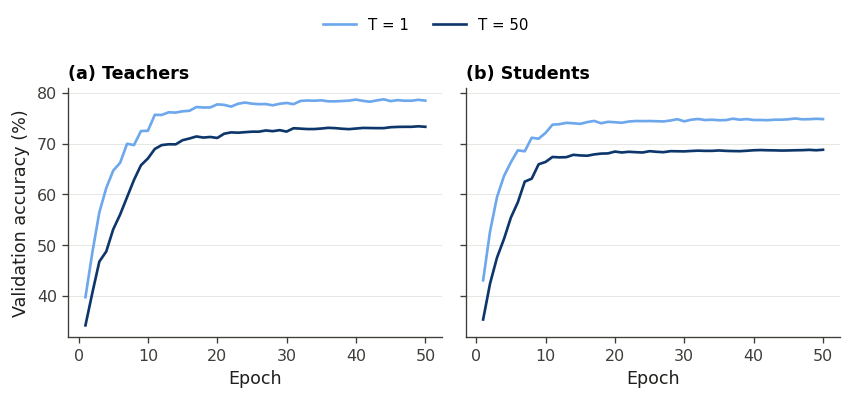

Reference (no distillation) val accuracy: 78.48% | flags: gap > 2.0, still improving (late gain > 0.5), declining (late drop > 1.0), no history

           model | train acc |  val acc |    gap | late gain | late drop | test acc | check
  teacher_T1_e50 |    75.34% |   78.48% |   0.00 |      0.06 |      0.22 |   78.48% | ok
  student_T1_e50 |    71.48% |   74.84% |   3.64 |      0.16 |      0.10 |   75.16% | NEEDS REVIEW (gap)
 teacher_T50_e50 |    68.63% |   73.32% |   5.16 |      0.23 |      0.08 |   73.07% | NEEDS REVIEW (gap)
 student_T50_e50 |    64.92% |   68.80% |   9.68 |      0.06 |      0.06 |   68.57% | NEEDS REVIEW (gap)

Some models need review. 'still improving' / 'gap': consider more epochs via EPOCHS_OVERRIDE (and report them). 'declining': check the optimization settings before adding epochs.


In [11]:
# Validation accuracy during training (light = low T, dark = high T)
temperature_colors = [TEMPERATURE_CMAP(i / max(len(TEMPERATURES) - 1, 1)) for i in range(len(TEMPERATURES))]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
for ax, role, title in zip(axes, ['teacher', 'student'], ['(a) Teachers', '(b) Students']):
    for T, color in zip(TEMPERATURES, temperature_colors):
        history = histories.get(model_name(role, T))
        if history is not None:
            ax.plot(range(1, len(history['val_acc']) + 1), history['val_acc'], color=color, linewidth=1.6, label=f'{T}')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, steps=[1, 2, 5, 10]))
axes[0].set_ylabel('Validation accuracy (%)')
fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
legend_above(fig, handles, [f'T = {l}' for l in labels], ncol=len(labels))
save_figure(fig, 'fig_validation_curves')
plt.show()


def late_gain(val_acc):
    """Mean val accuracy of the last 5 epochs minus the mean of the 5 epochs before."""
    return float(np.mean(val_acc[-5:]) - np.mean(val_acc[-10:-5]))


def late_drop(val_acc):
    """Best val accuracy minus the mean of the last 5 epochs."""
    return float(np.max(val_acc) - np.mean(val_acc[-5:]))


# Validation-performance check (not a proof of convergence). The test accuracy is reported but not used for any decision.
reference_val_acc = evaluate_model(teachers[1], valloader)   # model without distillation
print(f"Reference (no distillation) val accuracy: {reference_val_acc:.2f}% | flags: gap > {MAX_ACC_GAP}, "
      f"still improving (late gain > {MAX_LATE_GAIN}), declining (late drop > {MAX_LATE_DROP}), no history\n")
print(f"{'model':>16} | {'train acc':>9} | {'val acc':>8} | {'gap':>6} | {'late gain':>9} | {'late drop':>9} | "
      f"{'test acc':>8} | check")
validation_check = {}
for T in TEMPERATURES:
    for role, model in [('teacher', teachers[T]), ('student', students[T])]:
        name = model_name(role, T)
        history = histories.get(name)
        val_acc = evaluate_model(model, valloader)
        test_acc = evaluate_model(model, testloader)
        gap = reference_val_acc - val_acc

        flags = []
        if gap > MAX_ACC_GAP:
            flags.append('gap')
        train_acc = history['train_acc'][-1] if history else float('nan')
        if history is None or len(history['val_acc']) < 10:
            gain = drop = float('nan')
            flags.append('no history')
        else:
            gain, drop = late_gain(history['val_acc']), late_drop(history['val_acc'])
            if gain > MAX_LATE_GAIN:
                flags.append('still improving')
            if drop > MAX_LATE_DROP:
                flags.append('declining')

        validation_check[name] = {'train_acc': train_acc, 'val_acc': val_acc, 'gap': gap, 'late_gain': gain,
                                  'late_drop': drop, 'test_acc': test_acc, 'flags': flags}
        status = 'ok' if not flags else 'NEEDS REVIEW (' + ', '.join(flags) + ')'
        print(f"{name:>16} | {train_acc:8.2f}% | {val_acc:7.2f}% | {gap:6.2f} | {gain:9.2f} | {drop:9.2f} | "
              f"{test_acc:7.2f}% | {status}")
save_json(validation_check, 'validation_check.json')

if any(v['flags'] for v in validation_check.values()):
    print("\nSome models need review. 'still improving' / 'gap': consider more epochs via EPOCHS_OVERRIDE "
          "(and report them). 'declining': check the optimization settings before adding epochs.")


# Robustness Evaluation Against Adversarial Attacks

In [12]:
# The attack is done in [0,1] pixel space, so normalization is moved inside the model.
# Already-trained models can be wrapped without retraining.
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.247, 0.243, 0.261)

class NormalizedModel(nn.Module):
    """Takes [0,1] pixel inputs, normalizes them, then calls the original model."""
    def __init__(self, model, mean=CIFAR_MEAN, std=CIFAR_STD):
        super().__init__()
        self.model = model
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, x):
        return self.model((x - self.mean) / self.std)

# Test set for attacks: ToTensor only (no Normalize), pixels stay in [0,1]
transform_test_raw = transforms.Compose([transforms.ToTensor()])
testset_raw = CustomCIFAR10Dataset(root=root_path, train=False, transform=transform_test_raw)
testloader_raw = DataLoader(testset_raw, batch_size=128, shuffle=False, num_workers=num_workers)


In [13]:
def logit_margin(logits, labels):
    """z_y - max_{j != y} z_j for each sample (negative means misclassified)."""
    true_logit = logits.gather(1, labels[:, None]).squeeze(1)
    other_logits = logits.clone()
    other_logits.scatter_(1, labels[:, None], float('-inf'))
    return true_logit - other_logits.max(dim=1).values


def generate_pgd_adversarial_sample(model, inputs, labels, epsilon=8/255, alpha=2/255,
                                    num_iter=20, random_start=True, loss_type='ce', num_restarts=1):
    """
    Generate adversarial samples using PGD (L-infinity) in [0,1] pixel space.
    A sample counts as fooled as soon as ANY iterate (of any restart) is misclassified; that iterate is kept.
    The unperturbed input is part of the threat model, so samples that are already misclassified count as fooled.
    Args:
        model: The model to attack. Must take [0,1] pixel inputs (wrap it with NormalizedModel).
        inputs: Original inputs in [0,1] pixel space (e.g. from testloader_raw).
        labels: True labels for the inputs.
        epsilon: Maximum perturbation size (pixel units, e.g. 8/255).
        alpha: Step size for each iteration (pixel units, e.g. 2/255).
        num_iter: Number of iterations per restart.
        random_start: Start each restart from a random point inside the epsilon-ball.
        loss_type: 'ce'     -> maximize the cross-entropy loss (CE-PGD). Goes through the softmax, so its
                               gradient vanishes when the softmax saturates (gradient masking).
                   'margin' -> minimize the logit margin z_y - max_{j != y} z_j (Margin-PGD, as in the
                               Carlini-Wagner loss). Works on the logits directly, not affected by saturation.
        num_restarts: Number of independent restarts.
    Returns:
        adv_inputs: Adversarial inputs in [0,1] (the first misclassified iterate if one was found,
                    otherwise the last iterate of the last restart).
        fooled: Boolean tensor, True where a misclassified point within the epsilon-ball was found.
    """
    x_orig = inputs.detach()
    with torch.no_grad():
        fooled = model(x_orig).argmax(dim=1) != labels
    adv_inputs = x_orig.clone()

    for _ in range(num_restarts):
        x_adv = x_orig.clone()
        if random_start:
            x_adv = torch.clamp(x_adv + torch.empty_like(x_adv).uniform_(-epsilon, epsilon), 0, 1)

        for step in range(num_iter + 1):
            x_adv.requires_grad_(True)
            logits = model(x_adv)

            # Keep the first misclassified iterate of every sample
            newly_fooled = (logits.detach().argmax(dim=1) != labels) & ~fooled
            adv_inputs[newly_fooled] = x_adv.detach()[newly_fooled]
            fooled |= newly_fooled
            if step == num_iter:
                break

            if loss_type == 'ce':
                loss = F.cross_entropy(logits, labels)
            elif loss_type == 'margin':
                loss = -logit_margin(logits, labels).sum()
            else:
                raise ValueError("loss_type must be 'ce' or 'margin'.")
            grad, = torch.autograd.grad(loss, x_adv)

            # Gradient-sign ascent step, then project back to the epsilon-ball and the valid pixel range
            x_adv = x_adv.detach() + alpha * grad.sign()
            x_adv = torch.min(torch.max(x_adv, x_orig - epsilon), x_orig + epsilon)
            x_adv = torch.clamp(x_adv, 0, 1)

        adv_inputs[~fooled] = x_adv.detach()[~fooled]

    return adv_inputs.detach(), fooled


In [14]:
def test_robustness(model, testloader, loss_type='ce', epsilon=8/255, alpha=2/255, num_iter=20,
                    num_restarts=1, seed=0):
    """
    Test model robustness under a PGD attack.
    Args:
        model: The model to test. Must take [0,1] pixel inputs (wrap it with NormalizedModel).
        testloader: DataLoader yielding [0,1] pixel inputs (use testloader_raw).
        loss_type: 'ce' (CE-PGD) or 'margin' (Margin-PGD), see generate_pgd_adversarial_sample.
        epsilon: Perturbation size (pixel units).
        alpha: Step size (pixel units).
        num_iter: Number of PGD iterations per restart.
        num_restarts: Number of random restarts.
        seed: Seed for the random starts, reset at the beginning so every evaluation is reproducible.
    Returns:
        Dict with
          clean_accuracy:  accuracy on the unperturbed inputs (%),
          robust_accuracy: percentage of samples for which no misclassified point was found within the
                           epsilon-ball (the unperturbed input included), so robust <= clean accuracy,
          success_rate:    among samples that are correctly classified without perturbation,
                           the percentage for which the attack found a misclassified point.
    """
    model.eval()
    set_seed(seed)
    n_total = n_clean_correct = n_robust = n_flipped = 0

    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.no_grad():
            clean_correct = model(inputs).argmax(dim=1) == labels
        _, fooled = generate_pgd_adversarial_sample(model, inputs, labels, epsilon, alpha, num_iter,
                                                    loss_type=loss_type, num_restarts=num_restarts)
        n_total += labels.size(0)
        n_clean_correct += clean_correct.sum().item()
        n_robust += (~fooled).sum().item()                 # fooled already includes clean mistakes
        n_flipped += (clean_correct & fooled).sum().item()

    return {
        'clean_accuracy': 100 * n_clean_correct / n_total,
        'robust_accuracy': 100 * n_robust / n_total,
        'success_rate': 100 * n_flipped / max(n_clean_correct, 1),
    }


# PGD robustness: no distillation vs. distilled models at different temperatures

Both attacks use the same budget (L-infinity, epsilon = 8/255, step 2/255, 20 iterations, random start, `PGD_RESTARTS`
restarts). A sample counts as non-robust if any iterate is misclassified (or if it is already misclassified without
perturbation), so robust accuracy never exceeds clean accuracy.

**CE-PGD** follows the cross-entropy gradient and is expected to suffer from gradient masking at high T;
**Margin-PGD** follows the logit margin and is not affected by softmax saturation. If distilled models look robust
under CE-PGD but not under Margin-PGD, the apparent robustness comes from gradient masking.

In [15]:
# Evaluate all models with CE-PGD and Margin-PGD in [0,1] pixel space
ATTACKS = {'CE-PGD': 'ce', 'Margin-PGD': 'margin'}
PGD_SETTINGS = {'norm': 'Linf', 'epsilon': 8/255, 'alpha': 2/255, 'num_iter': 20,
                'num_restarts': 1, 'random_start': True, 'seed': 0}
PGD_RESTARTS = PGD_SETTINGS['num_restarts']

models_to_test = {'No distillation': teachers[1]}
models_to_test.update({f'T={T}': students[T] for T in TEMPERATURES})
model_names = {'No distillation': model_name('teacher', 1)}
model_names.update({f'T={T}': model_name('student', T) for T in TEMPERATURES})

results = {}
for name, model in models_to_test.items():
    wrapped_model = NormalizedModel(model).to(device).eval()
    results[name] = {'checkpoint': model_names[name]}
    for attack_name, loss_type in ATTACKS.items():
        r = test_robustness(wrapped_model, testloader_raw, loss_type=loss_type,
                            epsilon=PGD_SETTINGS['epsilon'], alpha=PGD_SETTINGS['alpha'],
                            num_iter=PGD_SETTINGS['num_iter'], num_restarts=PGD_SETTINGS['num_restarts'],
                            seed=PGD_SETTINGS['seed'])
        results[name]['clean_accuracy'] = r['clean_accuracy']
        results[name][attack_name] = {'robust_accuracy': r['robust_accuracy'], 'success_rate': r['success_rate']}
        print(f"{name:>16} | {attack_name:>10}: clean {r['clean_accuracy']:.2f}%, robust {r['robust_accuracy']:.2f}%, "
              f"success rate {r['success_rate']:.2f}% (of correctly classified samples)")

save_json({'settings': PGD_SETTINGS, 'results': results}, 'pgd_results.json')


 No distillation |     CE-PGD: clean 78.48%, robust 0.00%, success rate 100.00% (of correctly classified samples)
 No distillation | Margin-PGD: clean 78.48%, robust 0.00%, success rate 100.00% (of correctly classified samples)
             T=1 |     CE-PGD: clean 75.16%, robust 0.00%, success rate 100.00% (of correctly classified samples)
             T=1 | Margin-PGD: clean 75.16%, robust 0.00%, success rate 100.00% (of correctly classified samples)
            T=50 |     CE-PGD: clean 68.57%, robust 42.85%, success rate 37.51% (of correctly classified samples)
            T=50 | Margin-PGD: clean 68.57%, robust 0.48%, success rate 99.30% (of correctly classified samples)


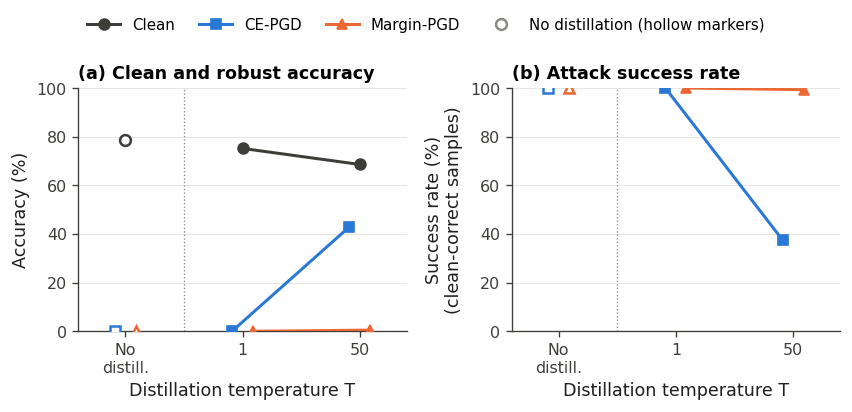

PGD: L-inf, epsilon = 0.0314 (8/255), step = 0.0078 (2/255), 20 iterations, 1 restart(s), random start.


In [16]:
# Clean / robust accuracy and attack success rate vs. distillation temperature.
# Ordinal x-axis: the first position is the model without distillation (hollow markers),
# separated by a dotted line from the distilled models at increasing T (filled markers).
model_keys = ['No distillation'] + [f'T={T}' for T in TEMPERATURES]
x = np.arange(len(model_keys))
x_labels = ['No\ndistill.'] + [str(T) for T in TEMPERATURES]


# Small horizontal offsets so that the two attacks never hide each other's markers
DODGE = {'Clean': 0.0, 'CE-PGD': -0.09, 'Margin-PGD': 0.09}


def plot_vs_temperature(ax, values, color, marker, label):
    xs = x + DODGE[label]
    ax.plot(xs[1:], values[1:], color=color, marker=marker, label=label, zorder=3)
    ax.plot(xs[:1], values[:1], linestyle='none', marker=marker, color=color,
            markerfacecolor='white', markeredgewidth=1.5, zorder=3)


def format_temperature_axis(ax):
    ax.axvline(0.5, color=COLORS['reference'], linewidth=0.8, linestyle=':')
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels)
    ax.set_xlim(-0.4, len(x) - 0.6)
    ax.set_xlabel('Distillation temperature T')


hollow_handle = Line2D([], [], linestyle='none', marker='o', color=COLORS['reference'],
                       markerfacecolor='white', markeredgewidth=1.5, label='No distillation (hollow markers)')

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1))
ax = axes[0]
plot_vs_temperature(ax, [results[k]['clean_accuracy'] for k in model_keys], COLORS['clean'], 'o', 'Clean')
plot_vs_temperature(ax, [results[k]['CE-PGD']['robust_accuracy'] for k in model_keys], COLORS['ce'], 's', 'CE-PGD')
plot_vs_temperature(ax, [results[k]['Margin-PGD']['robust_accuracy'] for k in model_keys], COLORS['margin'], '^', 'Margin-PGD')
ax.set_ylabel('Accuracy (%)')
ax.set_title('(a) Clean and robust accuracy')
ax.set_ylim(0, 100)
format_temperature_axis(ax)

ax = axes[1]
plot_vs_temperature(ax, [results[k]['CE-PGD']['success_rate'] for k in model_keys], COLORS['ce'], 's', 'CE-PGD')
plot_vs_temperature(ax, [results[k]['Margin-PGD']['success_rate'] for k in model_keys], COLORS['margin'], '^', 'Margin-PGD')
ax.set_ylabel('Success rate (%)\n(clean-correct samples)')
ax.set_title('(b) Attack success rate')
ax.set_ylim(0, 100)
format_temperature_axis(ax)

fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
legend_above(fig, handles + [hollow_handle], labels + [hollow_handle.get_label()], ncol=4)
save_figure(fig, 'fig_accuracy_vs_temperature')
plt.show()
print(f"PGD: L-inf, epsilon = {PGD_SETTINGS['epsilon']:.4f} (8/255), step = {PGD_SETTINGS['alpha']:.4f} (2/255), "
      f"{PGD_SETTINGS['num_iter']} iterations, {PGD_SETTINGS['num_restarts']} restart(s), random start.")


# Average gradient norm

For each model we compute, per test sample, the gradient of a scalar function w.r.t. the **input in [0,1] pixel space**:

* **Cross-entropy loss** `CE(z(x), y)`: the gradient that CE-PGD (and the paper's sensitivity analysis) uses.
  It goes through the softmax, so it vanishes when the softmax saturates.
* **Logit margin** `m(x) = z_y(x) - max_{j != y} z_j(x)`: does not go through the softmax.

Norms: **L2** (overall input sensitivity) and **L1** (dual of L-infinity: for `||delta||_inf <= eps` the first-order
change of a function is at most `eps * ||grad||_1`, which is the PGD setting). `zero_frac` is the fraction of samples
whose gradient is exactly zero in float32.

**How to read the results.** Raw gradient norms depend on the overall scale of the logits: multiplying all logits by k
multiplies the margin gradient by k, but does not change any decision. Distilled models at high T have much larger
logits, so a large margin gradient does *not* mean a less smooth decision function. "Small CE gradient, large margin
gradient" is a diagnostic of softmax saturation only, and must be interpreted together with the CE-PGD / Margin-PGD results.

A **scale-invariant** quantity is the first-order (linearized) distance to the decision boundary,
`d_inf(x) = m(x) / ||grad m(x)||_1` (L-infinity) and `d_2(x) = m(x) / ||grad m(x)||_2` (L2): numerator and denominator
scale together. `d_inf` estimates the smallest L-infinity perturbation that flips the prediction (compare with
epsilon = 8/255), in the spirit of the paper's robustness metric (average minimum perturbation, Eq. 3-4).

All statistics are reported separately for **clean-correct** and **clean-wrong** samples, so the averages are not
dominated by misclassified samples. The distance is only meaningful for correctly classified samples (m > 0).

In [17]:
def input_gradient_stats(model, loader):
    """
    Per-sample input-gradient statistics on a dataset.
    Args:
        model: Model taking [0,1] pixel inputs (wrap it with NormalizedModel). Must be in eval mode.
        loader: DataLoader yielding [0,1] pixel inputs (use testloader_raw).
    Returns:
        Dict of numpy arrays (one entry per sample): ce_l2, ce_l1, margin_l2, margin_l1, margin, correct.
    """
    model.eval()
    out = {k: [] for k in ['ce_l2', 'ce_l1', 'margin_l2', 'margin_l1', 'margin', 'correct']}

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        inputs.requires_grad_(True)
        logits = model(inputs)
        margins = logit_margin(logits, labels)

        # Summing over the batch gives exact per-sample gradients: samples are independent in eval mode
        # (no batch normalization, dropout disabled).
        objectives = {'ce': F.cross_entropy(logits, labels, reduction='sum'), 'margin': margins.sum()}
        for key, objective in objectives.items():
            grad, = torch.autograd.grad(objective, inputs, retain_graph=(key == 'ce'))
            grad = grad.flatten(start_dim=1)
            out[f'{key}_l2'].append(grad.norm(p=2, dim=1).cpu())
            out[f'{key}_l1'].append(grad.norm(p=1, dim=1).cpu())
        out['margin'].append(margins.detach().cpu())
        out['correct'].append((logits.detach().argmax(dim=1) == labels).cpu())

    return {k: torch.cat(v).numpy() for k, v in out.items()}


def summarize_gradient_stats(s, epsilon=8/255):
    """Summaries for clean-correct and clean-wrong samples, plus the linearized distance for correct samples."""
    summary = {}
    for subset, mask in [('correct', s['correct']), ('wrong', ~s['correct'])]:
        summary[subset] = {'n': int(mask.sum())}
        for key in ['ce', 'margin']:
            l2, l1 = s[f'{key}_l2'][mask], s[f'{key}_l1'][mask]
            summary[subset][key] = {
                'mean_l2': float(l2.mean()) if mask.any() else float('nan'),
                'median_l2': float(np.median(l2)) if mask.any() else float('nan'),
                'mean_l1': float(l1.mean()) if mask.any() else float('nan'),
                'median_l1': float(np.median(l1)) if mask.any() else float('nan'),
                'zero_frac': float((l2 == 0).mean()) if mask.any() else float('nan'),
            }

    # Linearized distance to the decision boundary (scale-invariant), correct samples only
    mask = s['correct']
    m, l1, l2 = s['margin'][mask], s['margin_l1'][mask], s['margin_l2'][mask]
    with np.errstate(divide='ignore'):
        d_inf = np.where(l1 > 0, m / l1, np.inf)
        d_2 = np.where(l2 > 0, m / l2, np.inf)
    summary['distance'] = {
        'median_d_inf': float(np.median(d_inf)) if mask.any() else float('nan'),
        'median_d_2': float(np.median(d_2)) if mask.any() else float('nan'),
        'frac_d_inf_below_eps': float((d_inf < epsilon).mean()) if mask.any() else float('nan'),
        'n_infinite': int(np.isinf(d_inf).sum()),
    }
    return summary


In [18]:
# Gradient statistics on the clean test set: no distillation vs. students at each T
grad_results, grad_per_sample = {}, {}
for name, model in models_to_test.items():
    wrapped_model = NormalizedModel(model).to(device).eval()
    per_sample = input_gradient_stats(wrapped_model, testloader_raw)
    summary = summarize_gradient_stats(per_sample, epsilon=PGD_SETTINGS['epsilon'])
    grad_results[name] = summary
    grad_per_sample[name] = per_sample

    c, w, d = summary['correct'], summary['wrong'], summary['distance']
    print(f"{name:>16} | correct (n={c['n']}): CE median L2 {c['ce']['median_l2']:.3e}, zero {100 * c['ce']['zero_frac']:.1f}% | "
          f"margin median L2 {c['margin']['median_l2']:.3e}")
    print(f"{'':>16} | wrong   (n={w['n']}): CE median L2 {w['ce']['median_l2']:.3e}, zero {100 * w['ce']['zero_frac']:.1f}% | "
          f"margin median L2 {w['margin']['median_l2']:.3e}")
    print(f"{'':>16} | linearized distance (correct): median d_inf {d['median_d_inf']:.4f} "
          f"(eps = {PGD_SETTINGS['epsilon']:.4f}), below eps {100 * d['frac_d_inf_below_eps']:.1f}%, "
          f"median d_2 {d['median_d_2']:.4f}")

save_json({'checkpoints': model_names, 'results': grad_results}, 'gradient_norms.json')
np.savez(os.path.join(OUTPUT_DIR, 'gradient_norms_per_sample.npz'),
         **{f'{name}|{key}': values for name, d in grad_per_sample.items() for key, values in d.items()})


 No distillation | correct (n=7848): CE median L2 1.389e+00, zero 0.0% | margin median L2 2.030e+01
                 | wrong   (n=2152): CE median L2 1.475e+01, zero 0.0% | margin median L2 2.046e+01
                 | linearized distance (correct): median d_inf 0.0040 (eps = 0.0314), below eps 100.0%, median d_2 0.1529
             T=1 | correct (n=7516): CE median L2 1.662e+00, zero 0.0% | margin median L2 1.220e+01
                 | wrong   (n=2484): CE median L2 9.511e+00, zero 0.0% | margin median L2 1.342e+01
                 | linearized distance (correct): median d_inf 0.0047 (eps = 0.0314), below eps 100.0%, median d_2 0.1774
            T=50 | correct (n=6857): CE median L2 0.000e+00, zero 69.2% | margin median L2 3.102e+02
                 | wrong   (n=3143): CE median L2 3.162e+02, zero 0.0% | margin median L2 3.217e+02
                 | linearized distance (correct): median d_inf 0.0087 (eps = 0.0314), below eps 98.0%, median d_2 0.3337


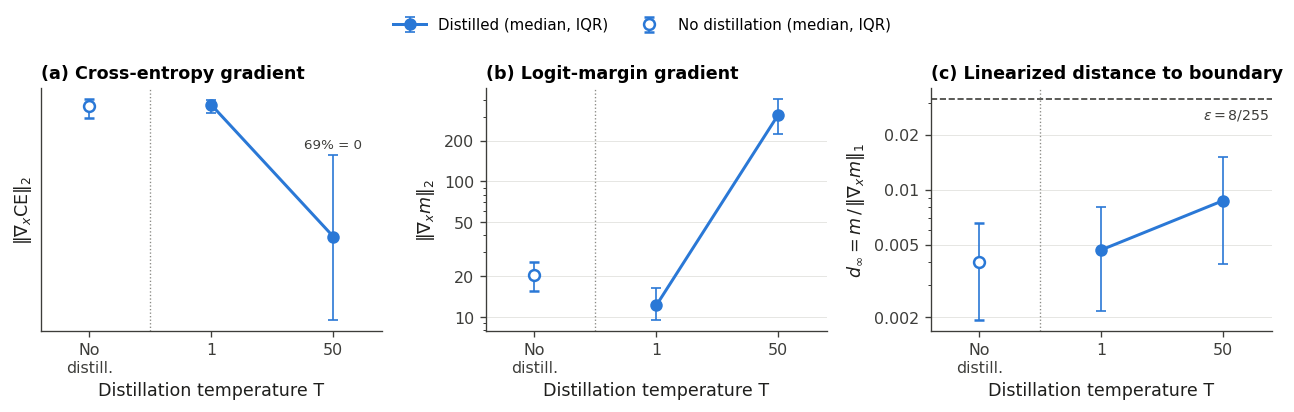

In [19]:
# Gradient statistics on clean-correct samples vs. temperature: median with interquartile range (25th-75th percentile).
# Same ordinal x-axis as the accuracy figure (hollow = no distillation). Log scale on y.
# Samples with an exactly zero value cannot be shown on a log scale; their fraction is written above the point.
def median_iqr(values):
    """Median and asymmetric IQR error bars of the positive values, plus the fraction of non-positive values."""
    positive = values[np.isfinite(values) & (values > 0)]
    zero_frac = 1 - len(positive) / max(len(values), 1)
    if len(positive) == 0:
        return np.nan, 0.0, 0.0, zero_frac
    q1, med, q3 = np.percentile(positive, [25, 50, 75])
    return med, med - q1, q3 - med, zero_frac


def linearized_distance(s):
    with np.errstate(divide='ignore', invalid='ignore'):
        return s['margin'] / s['margin_l1']


quantities = [
    ('(a) Cross-entropy gradient', r'$\|\nabla_x \mathrm{CE}\|_2$', lambda s: s['ce_l2']),
    ('(b) Logit-margin gradient', r'$\|\nabla_x m\|_2$', lambda s: s['margin_l2']),
    ('(c) Linearized distance to boundary', r'$d_\infty = m \,/\, \|\nabla_x m\|_1$', linearized_distance),
]

fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.1))
for ax, (title, ylabel, get) in zip(axes, quantities):
    stats = [median_iqr(get(grad_per_sample[k])[grad_per_sample[k]['correct']]) for k in model_keys]
    med = np.array([s[0] for s in stats])
    err = np.array([[s[1] for s in stats], [s[2] for s in stats]])
    ax.errorbar(x[1:], med[1:], yerr=err[:, 1:], color=COLORS['ce'], marker='o', capsize=3, elinewidth=1,
                label='Distilled', zorder=3)
    ax.errorbar(x[:1], med[:1], yerr=err[:, :1], color=COLORS['ce'], marker='o', markerfacecolor='white',
                markeredgewidth=1.5, capsize=3, elinewidth=1, linestyle='none', label='No distillation', zorder=3)
    for xi, (m, lo, hi, zero_frac) in zip(x, stats):
        if zero_frac > 0 and np.isfinite(m):
            ax.annotate(f'{100 * zero_frac:.0f}% = 0', (xi, m + hi), textcoords='offset points', xytext=(0, 4),
                        ha='center', fontsize=8, color=COLORS['clean'])
    if title.startswith('(c)'):
        ax.axhline(PGD_SETTINGS['epsilon'], color=COLORS['clean'], linestyle='--', linewidth=1)
        ax.annotate(r'$\epsilon = 8/255$', (len(x) - 0.6, PGD_SETTINGS['epsilon']), textcoords='offset points',
                    xytext=(-2, -12), ha='right', fontsize=8.5, color=COLORS['clean'])
    ax.set_yscale('log')
    # Ticks at 1, 2, 5 x 10^k so that narrow log ranges still get readable labels
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))   # plain numbers: 0.001, 0.002, 1, 2, 5
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs='auto'))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.grid(True, axis='y', which='major')
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    format_temperature_axis(ax)
fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
legend_above(fig, handles, ['Distilled (median, IQR)', 'No distillation (median, IQR)'], ncol=2)
save_figure(fig, 'fig_gradients_vs_temperature')
plt.show()
